In [ ]:
import numpy as np
from scipy.integrate import odeint
import tensorflow as tf
import matplotlib.pyplot as plt
#from utils_NSS_SINDy import *
import time
from datetime import datetime

In [ ]:
#%% Import packages
import numpy as np
import tensorflow as tf
from scipy.linalg import qr
import time

#%% Define functions here
# =============================================================================
# Define the ODE of Van der Pol
# =============================================================================
def  VanderPol(u,t,p):
    du1=u[1]
    du2=p[0]*(1-u[0]**2)*u[1]-u[0]

    du=np.array([du1,du2])

    #p0=0.5

    return du

# =============================================================================
# Define the ODE of Duffing
# =============================================================================
def  Duffing(u,t,p):
    du1=u[1]
    du2=-p[0]*u[1]-p[1]*u[0]-p[2]*u[0]**3

    du=np.array([du1,du2])

    #p0=[0.2,0.05,1]

    return du

# =============================================================================
# Define the ODE of Lotka
# =============================================================================
def  Lotka(u,t,p):
    du1=p[0]*u[0]-p[1]*u[0]*u[1]
    du2=p[1]*u[0]*u[1]-2*p[0]*u[1]

    du=np.array([du1,du2])

    #p0=[1,10]

    return du

# =============================================================================
# Define the ODE for cubic oscalator
# =============================================================================
def CubicOsc(u,t,p):
    du1=p[0]*u[0]**3+p[1]*u[1]**3
    du2=p[2]*u[0]**3+p[3]*u[1]**3

    du=np.array([du1,du2])

    #p0=[-0.1,2,-2,-0.1]

    return du

# =============================================================================
# Define the ODE for the Lorenz system
# =============================================================================
def Lorenz(u, t, p):
   du1 = p[0]*u[0]+p[1]*u[1]
   du2 = p[2]*u[0]+p[3]*u[0]*u[2]+p[4]*u[1]
   du3 = p[5]*u[0]*u[1]+p[6]*u[2]

   du=np.array([du1,du2,du3])

   #p0=[-10.0,10.0,28.0,-1.0,-1.0,1.0,-8/3]

   return du

# =============================================================================
# Define the library function for the SINDy
# =============================================================================
def Lib(x,libOrder):
    # First get the dimension of the x
    n,m=x.shape

    print("The first dimension of the input data:",n)
    print("The second dimension of the input data:",m)

    # Lib order 0
    # Theta=np.ones((n,1),dtype=float)
    Theta=x[:,[0]]

    # Lib order 1
    if libOrder>=1:
        for i in range(1,m):
            Theta=np.concatenate((Theta,x[:,[i]]),axis=1)

    if libOrder>=2:
        for i in range(m):
            for j in range(i,m):
                NewTerm=x[:,[i]]*x[:,[j]]
                Theta=np.concatenate((Theta,NewTerm),axis=1)

    if libOrder>=3:
        for i in range(m):
            for j in range(i,m):
                for k in range(j,m):
                    NewTerm=x[:,[i]]*x[:,[j]]*x[:,[k]]
                    Theta=np.concatenate((Theta,NewTerm),axis=1)

    if libOrder>=4:
        for i in range(m):
            for j in range(i,m):
                for k in range(j,m):
                    for ij in range(k,m):
                        NewTerm=x[:,[i]]*x[:,[j]]*x[:,[k]]*x[:,[ij]]
                        Theta=np.concatenate((Theta,NewTerm),axis=1)
    if libOrder>=5:
            for i in range(m):
                for j in range(i,m):
                    for k in range(j,m):
                        for ij in range(k,m):
                            for ik in range(ij,m):
                                NewTerm=x[:,[i]]*x[:,[j]]*x[:,[k]]*x[:,[ij]]*x[:,[ik]]
                                Theta=np.concatenate((Theta,NewTerm),axis=1)

    return Theta

# =============================================================================
# Define the library function for the SINDy: GPU version
# =============================================================================
@tf.function
def LibGPU(x):
    # =============================================================================
    # Following is the 3nd order lib for 2 dimentional system
    # =============================================================================
    z1=tf.gather(x,[0],axis=1)
    z2=tf.gather(x,[1],axis=1)

    Theta=tf.concat([z1,z2,z1**2,z1*z2,z2**2,z1**3,(z1**2)*z2,z1*(z2**2),z2**3],axis=1)

    # =============================================================================
    # Following is the 2nd order lib for 3 dimentional system
    # =============================================================================
    # z1=tf.gather(x,[0],axis=1)
    # z2=tf.gather(x,[1],axis=1)
    # z3=tf.gather(x,[2],axis=1)


    # Theta=tf.concat([z1,z2,z3,z1**2,z1*z2,z1*z3,z2**2,z2*z3,z3**2],axis=1)

    return Theta

# =============================================================================
# Define the function for calculating the derivative
# =============================================================================
def CalDerivative(x,dx,d):
    # First we get the information of the data length. The x should be a n x m vector.
    Dev=np.zeros(x.shape)
    n,m=x.shape

    # Define the coeficient for different orders of derivative
    if d==1:
        p1=1/12
        p2=-2/3
        p3=0
        p4=2/3
        p5=-1/12
    elif d==2:
        p1=-1/12
        p2=4/3
        p3=-5/2
        p4=4/3
        p5=-1/12
    elif d==3:
        p1=-1/2
        p2=1
        p3=0
        p4=-1
        p5=1/2


    # Calculate the derivative of the middel point
    for i in range(2,n-2):
        Dev[i,:]=(p1*x[i-2,:]+p2*x[i-1,:]+p3*x[i,:]+p4*x[i+1,:]+p5*x[i+2,:])
        if d==1:
            Dev[i,:]=Dev[i,:]/dx
        elif d==2:
            Dev[i,:]=Dev[i,:]/dx^2
        elif d==3:
            Dev[i,:]=Dev[i,:]/dx^3

    # Ge the derivative of first two points using forward difference
    if d==1:
        q1=-3/2
        q2=2
        q3=-1/2
        q4=0
        q5=0
    elif d==2:
        q1=2
        q2=-5
        q3=4
        q4=-1
        q5=0
    elif d==3:
        q1=-5/2
        q2=9
        q3=-12
        q4=7
        q5=-3/2

    for i in range(2):
        Dev[i,:]=(q1*x[i,:]+q2*x[i+1,:]+q3*x[i+2,:]+q4*x[i+3,:]+q5*x[i+4,:])
        if d==1:
            Dev[i,:]=Dev[i,:]/dx;
        elif d==2:
            Dev[i,:]=Dev[i,:]/dx^2;
        elif d==3:
            Dev[i,:]=Dev[i,:]/dx^3;


    # Get the derivative of last two points using backward difference
    if d==1:
        m1=3/2,
        m2=-2,
        m3=1/2,
        m4=0,
        m5=0
    elif d==2:
        m1=2
        m2=-5
        m3=4
        m4=-1
        m5=0
    elif d==3:
        m1=5/2
        m2=-9
        m3=12
        m4=-7
        m5=3/2

    for i in range(n-2,n):
        Dev[i,:]=(m1*x[i,:]+m2*x[i-1,:]+m3*x[i-2,:]+m4*x[i-3,:]+m5*x[i-4,:])
        if d==1:
            Dev[i,:]=Dev[i,:]/dx;
        elif d==2:
            Dev[i,:]=Dev[i,:]/dx^2;
        elif d==3:
            Dev[i,:]=Dev[i,:]/dx^3;

    return Dev

# =============================================================================
# Define a function that solves the Matlab version of backslash
# Reference: https://pythonquestion.com/post/how-can-i-obtain-the-same-special-solutions-to-underdetermined-linear-systems-that-matlab-s-a-b-mldivide-operator-returns-using-numpy-scipy/
# =============================================================================
def solve_minnonzero(A, b):
    x1, res, rnk, s = np.linalg.lstsq(A, b,rcond=None)
    if rnk == A.shape[1]:
        return x1   # nothing more to do if A is full-rank
    Q, R, P = qr(A.T, mode='full', pivoting=True)
    Z = Q[:, rnk:].conj()
    C = np.linalg.solve(Z[rnk:], -x1[rnk:])
    return x1 + Z.dot(C)

# =============================================================================
# Define the function for the SINDy regression
# =============================================================================
def SINDy(Theta,dXdt,lam,N_iter,disp,NormalizeLib):
    # Coded By: K.Kahirman
    # Last Updated: May 18th, 2020
    n,m1=Theta.shape

    normLib=np.zeros((m1,1))

    # Normalize the library data
    n,m1=Theta.shape

    normLib=np.zeros((m1,1))

    # Normalize the library data
    if NormalizeLib==1:
        for norm_k in range(m1):
                normLib[norm_k] = np.linalg.norm(Theta[:,norm_k])
                Theta[:,norm_k] = Theta[:,norm_k]/normLib[norm_k]

    # Peform sparse regression
    Xi = solve_minnonzero(Theta,dXdt) # initial guess: Least-squares
    #Xi=np.transpose(ridge_regression(Theta,dXdt,0.05))

    n,m=dXdt.shape

    # lambda is our sparsification parameter.
    for k in range(N_iter):
        smallinds = (np.abs(Xi)<lam)
        Xi[smallinds]=0
        for ind in range(m):
            biginds = ~smallinds[:,ind]
            # Regress dynamics onto remaining terms to find sparse Xi
            # =============================================================================
            # Note that the following code all solves the problem Ax=b, but they solve it differently, here we will use the Matlab version of backslash(\)
            # Xi[biginds,ind] = np.linalg.lstsq(Theta[:,biginds],dXdt[:,ind],rcond=None)[0]
            # Xi[biginds,ind] = np.matmul(np.linalg.pinv(Theta[:,biginds]),dXdt[:,ind])
            Xi[biginds,ind]=solve_minnonzero(Theta[:,biginds],dXdt[:,ind])
            #Xi[biginds,ind]=np.transpose(ridge_regression(Theta[:,biginds],dXdt[:,ind],0.05))

    # Now retrive the parameters
    if NormalizeLib==1:
        for norm_k in range(m1):
            Xi[norm_k,:] = Xi[norm_k,:]/normLib[norm_k]

    ## Choose whether you want to display the final discovered equation

    if disp==1:
         print(Xi)

    return Xi

# =============================================================================
# Check whether the GPU is available
# =============================================================================
def CheckGPU():
    if tf.test.is_gpu_available():
        print("\n\n\n\n\n")
        print("The GPU is available")
        print("\n\n\n\n\n")
    else:
        print("\n\n\n\n\n")
        print("The GPU is not available")
        print("\n\n\n\n\n")
    return None

# =============================================================================
# Define the RK45 for the SINDy method
# =============================================================================
@tf.function
def RK45_F_SINDy(xin,LibGPU,Xi,dt):
    K1=tf.linalg.matmul(LibGPU(xin),Xi)*dt

    K2=tf.linalg.matmul(LibGPU(tf.math.add(xin,tf.constant(0.5)*K1)),Xi)*dt

    K3=tf.linalg.matmul(LibGPU(tf.math.add(xin,tf.constant(0.5)*K2)),Xi)*dt

    K4=tf.linalg.matmul(LibGPU(tf.math.add(xin,K3)),Xi)*dt

    return tf.math.add_n([xin,tf.constant(1/6)*K1,tf.constant(1/3)*K2,tf.constant(1/3)*K3,tf.constant(1/6)*K4])

# =============================================================================
# Define the RK45 for the SINDy method
# =============================================================================
@tf.function
def RK45_B_SINDy(xin,LibGPU,Xi,dt):
    K1=-tf.linalg.matmul(LibGPU(xin),Xi)*dt

    K2=-tf.linalg.matmul(LibGPU(tf.math.add(xin,tf.constant(0.5)*K1)),Xi)*dt

    K3=-tf.linalg.matmul(LibGPU(tf.math.add(xin,tf.constant(0.5)*K2)),Xi)*dt

    K4=-tf.linalg.matmul(LibGPU(tf.math.add(xin,K3)),Xi)*dt

    return tf.math.add_n([xin,tf.constant(1/6)*K1,tf.constant(1/3)*K2,tf.constant(1/3)*K3,tf.constant(1/6)*K4])

# =============================================================================
# Define a function that will generate multiple initial condtion for the forward and backward simulation.
# The input tensor should be n x m where the n is the number of states and m is the time horizon.
# =============================================================================
def GetInitialCondition(X,q,n):
    if q<0:
        raise Exception("The prediction step must be equals or greater than zero")
    else:
        X0=X[q:n-q,:]

    return X0

# =============================================================================
# Define a function that will slice the data provided
# =============================================================================
def SliceData(Y,q,dataLen):
    if q==0:
        Ypre_F=Y
        Ypre_B=Y
    elif q<0:
        raise Exception("The prediction step must be equals or greater than zero")
    else:
        Ypre_F=[]
        Ypre_B=[]
        for j in range(1,q+1):
            if j==1:
                Ypre_F=Y[q+j:dataLen-q+j,:]
                Ypre_B=Y[q-j:dataLen-q-j,:]
            else:
                Ypre_F=np.append(Ypre_F,Y[q+j:dataLen-q+j,:],axis=1)
                Ypre_B=np.append(Ypre_B,Y[q-j:dataLen-q-j,:],axis=1)

    return Ypre_F,Ypre_B

# =============================================================================
# Define a function that will slice the noise variable into future and previous state
# =============================================================================
@tf.function
def SliceNoise(NoiseVar,q,dataLen,stateVar):
    if q==0:
        NoiseVar_F=Noise
        NoiseVar_B=Noise
    elif q<0:
        raise Exception("The prediction step must be equals or greater than zero")
    else:
        NoiseVar_F=tf.slice(NoiseVar,[q+1,0],[dataLen-2*q,stateVar])
        NoiseVar_B=tf.slice(NoiseVar,[q-1,0],[dataLen-2*q,stateVar])

        for i in range(1,q):
            NoiseVar_F=tf.concat([NoiseVar_F,tf.slice(NoiseVar,[q+1+i,0],[dataLen-2*q,stateVar])],axis=1)
            NoiseVar_B=tf.concat([NoiseVar_B,tf.slice(NoiseVar,[q-1-i,0],[dataLen-2*q,stateVar])],axis=1)

    return NoiseVar_F,NoiseVar_B

# =============================================================================
# Define a function will calculate the prediction result given initial condition matrix and prediction step.
# This is the SINDy version
# =============================================================================
@tf.function
def Prediction_SINDy(X0,LibGPU,dt,q,stateVar,dataLen,Xi):
    if q==0:
        Xpre_F=X0
        Xpre_B=X0
    elif q<0:
        raise Exception("The prediction step must be equals or greater than zero")
    else:
        Xpre_F=RK45_F_SINDy(X0,LibGPU,Xi,dt)
        Xpre_B=RK45_B_SINDy(X0,LibGPU,Xi,dt)

        for i in range(q-1):
            Xpre_F=tf.concat([Xpre_F,RK45_F_SINDy(tf.slice(Xpre_F,[0,stateVar*i],[dataLen-2*q,stateVar]),LibGPU,Xi,dt)],axis=1)
            Xpre_B=tf.concat([Xpre_B,RK45_B_SINDy(tf.slice(Xpre_B,[0,stateVar*i],[dataLen-2*q,stateVar]),LibGPU,Xi,dt)],axis=1)

    return Xpre_F,Xpre_B

# =============================================================================
# Define a function that calculate the decay factor
# =============================================================================
def DecayFactor(ro,stateVar,q):
    if q==0:
        weights=1
    elif q<0:
        raise Exception("The prediction step must be equals or greater than zero")
    else:
        weights=[]
        for j in range(q):
            for i in range(stateVar):
                weights=np.append(weights,ro**(j))

    return weights

# =============================================================================
# Calculate the derivative of the measurement. The first two and lst two point will be discarded.
# =============================================================================
@tf.function
def CalDerivativeMatrix(Y,dataLen,stateVar,dt):
    p1=tf.constant(1/12)
    p2=tf.constant(-2/3)
    p3=tf.constant(0.0)
    p4=tf.constant(2/3)
    p5=tf.constant(-1/12)

    Dev=tf.math.add_n([tf.math.multiply(p1,tf.slice(Y,[0,0],[dataLen-4,stateVar])),\
                   tf.math.multiply(p2,tf.slice(Y,[1,0],[dataLen-4,stateVar])),\
                   tf.math.multiply(p3,tf.slice(Y,[2,0],[dataLen-4,stateVar])),\
                   tf.math.multiply(p4,tf.slice(Y,[3,0],[dataLen-4,stateVar])),\
                   tf.math.multiply(p5,tf.slice(Y,[4,0],[dataLen-4,stateVar]))])/dt

    return Dev

# =============================================================================
# Define a function that calculate the weighted mean suqare error
# =============================================================================
@tf.function
def WeightMSE(Yt_F,Xp_F,Yt_B,Xp_B,NoiseVar_F,NoiseVar_B,weights):
    # Calculate the prediction of noisy data
    Yp_F=Xp_F+NoiseVar_F
    Yp_B=Xp_B+NoiseVar_B

    # Calculate the loss
    Jwmse_F=tf.reduce_mean(tf.math.multiply(tf.math.squared_difference(Yt_F,Yp_F),weights))
    Jwmse_B=tf.reduce_mean(tf.math.multiply(tf.math.squared_difference(Yt_B,Yp_B),weights))

    Jwmse=tf.math.add(Jwmse_F,Jwmse_B)

    return Jwmse

# =============================================================================
# Define the one step loss function for the noise signal speration: SINDy approach
# =============================================================================
@tf.function
def OneStepLoss_NSS_SINDy(Y,Y0,Ypre_F,Ypre_B,NoiseVar,Xi,Xi_act,weights,dt,q,stateVar,dataLen,LibGPU,optimizer):
    with tf.GradientTape() as g:
        # First get the initial condition guess based on the measurement data and noise variable
        X0=tf.math.subtract(Y0,tf.slice(NoiseVar,[q,0],[dataLen-2*q,stateVar]))

        # Then use the constraint
        Xi_var=tf.math.multiply(Xi,Xi_act)

        # Next, simulate the system forward and backward
        Xpre_F,Xpre_B=Prediction_SINDy(X0,LibGPU,dt,q,stateVar,dataLen,Xi_var)

        # Similarly get the forward and backward noise
        NoiseVar_F,NoiseVar_B=SliceNoise(NoiseVar,q,dataLen,stateVar)

        # Next calculate the weighted loss
        Jw=WeightMSE(Ypre_F,Xpre_F,Ypre_B,Xpre_B,NoiseVar_F,NoiseVar_B,weights)

        # Next calculate the derivative error
        Xes=tf.math.subtract(Y,NoiseVar)
        Xmid=tf.slice(Xes,[2,0],[dataLen-4,stateVar])
        dXes=CalDerivativeMatrix(Xes,dataLen,stateVar,dt)
        #Jd=tf.nn.l2_loss(tf.math.subtract(dXes,tf.linalg.matmul(LibGPU(Xmid),Xi_var)))
        Jd=1.0*tf.reduce_mean(tf.math.squared_difference(dXes,tf.linalg.matmul(LibGPU(Xmid),Xi_var)))

        # Finally, add all the noise together
        J=tf.add(Jw,Jd)

    # Calculate the gradient with respect to the variables
    gard=g.gradient(J,[Xi,NoiseVar])
    optimizer.apply_gradients(zip(gard,[Xi,NoiseVar]))

    return J

# =============================================================================
# Now define the training function for the noise signal speration: SINDy approach
# =============================================================================
def Train_NSS_SINDy(Y,Y0,Ypre_F,Ypre_B,NoiseVar,Xi,Xi_act,weights,dt,q,stateVar,dataLen,optimizer,N_train):
    start=time.time()
    for i in range(N_train):
        # Calculate the cost and updte the gradient
        J=OneStepLoss_NSS_SINDy(Y,Y0,Ypre_F,Ypre_B,NoiseVar,Xi,Xi_act,weights,dt,q,stateVar,dataLen,LibGPU,optimizer)

        if i%1000==0:
            tf.print(J)

    totoalTime=time.time()-start

    return NoiseVar.numpy(),totoalTime

# =============================================================================
# The below function will iterativly denoise the signal
# =============================================================================
def NSS_SINDy(xn,libOrder,Nloop,N_SINDy_Iter,NormalizeLib,disp,Y,Y0,Ypre_F,Ypre_B,NoiseVar,Xi,Xi_act,weights,dt,q,stateVar,dataLen,optimizer,N_train):
    start=time.time()
    for i in range(Nloop):
        # Do the signal noise speration with the initial guess
        NoiseID=Train_NSS_SINDy(Y,Y0,Ypre_F,Ypre_B,NoiseVar,Xi,Xi_act,weights,dt,q,stateVar,dataLen,optimizer,N_train)

        # After the first iteration, minus the noise identified from the noisy measurement data
        xes=xn-NoiseID
        dxes=CalDerivative(xes,dt,1)

        print("Current Xi result")
        print(Xi)

        # Do SINDy on the denoised data
        Theta=Lib(xes,libOrder)
        lam=0.1
        Xi0=SINDy(Theta,dxes,lam,N_SINDy_Iter,disp,NormalizeLib)

        # Determine which term should we focus on to optimize next
        Xi_act_dum=tf.constant((Xi0!=0).astype(np.float32),dtype=tf.dtypes.float32)
        Xi_act=tf.math.multiply(Xi_act,Xi_act_dum)
        Xi=tf.Variable(Xi0,dtype=tf.dtypes.float32)

        print("The SINDy loop ",str(i+1),"finished...")
        print("Current SINDy result")
        print(Xi0)
        print("After setting some of the values to zero")
        print(tf.math.multiply(Xi,Xi_act))

    totoalTime=time.time()-start

    return NoiseID,totoalTime,Xi.numpy(),Xi_act,Xi

# =============================================================================
# Define a function that calculates the noise signal speration accuracy
# =============================================================================
def ID_Accuracy_SINDy(x,dx,Noise,NoiseID,LibGPU,Xi,dataLen,dt):
    Enoise_error=np.linalg.norm(Noise-NoiseID,'fro')**2/dataLen
    Evector_field_error=np.linalg.norm(dx-tf.linalg.matmul(LibGPU(tf.constant(x,dtype='float32')),Xi),'fro')**2/np.linalg.norm(dx,'fro')**2

    xpre=[]
    xpre=RK45_F_SINDy(tf.constant([x[0,:]],dtype="float32"),LibGPU,Xi,dt).numpy()

    try:
        for i in range(1,dataLen-1):
            dummy=RK45_F_SINDy(tf.constant([xpre[-1]],dtype="float32"),LibGPU,Xi,dt).numpy()
            xpre=np.append(xpre,[dummy[0]],axis=0)

        Epre_error=np.linalg.norm(x[1:]-xpre,'fro')**2/np.linalg.norm(x,'fro')**2
    except:
        print("The simulation blows up...Current Neural Network is not stable...")
        Epre_error=float('nan')

    return Enoise_error,Evector_field_error,Epre_error,xpre

# =============================================================================
# Define a function that will generate gasiian
# =============================================================================
def Gaussian(x, mu, sig):
    return np.exp(-np.power(x - mu, 2.) / (2 * np.power(sig, 2.)))

# =============================================================================
# This code is used for approximate the noise that we added into the signal.
# Reference: https://github.com/snagcliffs/RKNN
# =============================================================================
def approximate_noise(Y, lam):
	n,m = Y.shape

	D = np.zeros((m,m))
	D[0,:4] = [2,-5,4,-1]
	D[m-1,m-4:] = [-1,4,-5,2]

	for i in range(1,m-1):
	    D[i,i] = -2
	    D[i,i+1] = 1
	    D[i,i-1] = 1

	D = D.dot(D)

	X_smooth = np.vstack([np.linalg.solve(np.eye(m) + lam*D.T.dot(D), Y[j,:].reshape(m,1)).reshape(1,m) for j in range(n)])

	N_hat = Y-X_smooth

	return N_hat, X_smooth

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.








The GPU is not available






The first dimension of the input data: 1500
The second dimension of the input data: 2
[[ 0.74140354  0.3496646 ]
 [ 0.21843209 -0.37027741]
 [ 0.          0.        ]
 [-0.39887381  0.        ]
 [ 0.          0.        ]
 [ 0.          0.        ]
 [ 0.          0.        ]
 [ 0.          0.        ]
 [ 0.          0.        ]]
Runing the loop  1
5507.7124
561.191528
88.4966125
	 Current loop takes  18.395979166030884
Current Xi result
<tf.Variable 'Variable:0' shape=(9, 2) dtype=float32, numpy=
array([[ 1.4484773 ,  0.00225859],
       [-0.14932871, -1.2459415 ],
       [-0.09262381, -0.00747439],
       [-1.3496208 , -0.14172429],
       [ 0.34673354, -0.09147135],
       [ 0.00746572,  0.00282495],
       [ 0.04659967,  0.03527441],
       [ 0.06727999,  0.05405485],
       [-0.0344355 ,  0.00561631]], dtype=float32)>
The first dimension of the input data: 1496
The second dimension of the input data: 2
New Xi result
[[ 1.00002361  0.        ]
 [-

Text(0.5, 0, 'Loop Index')

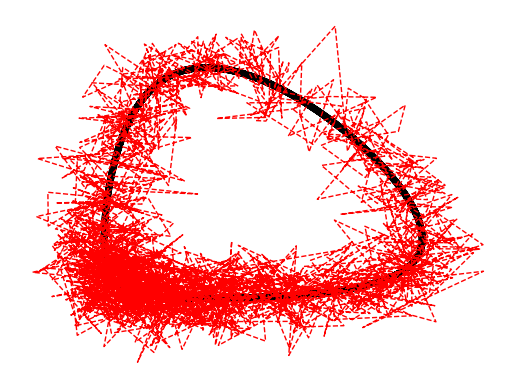

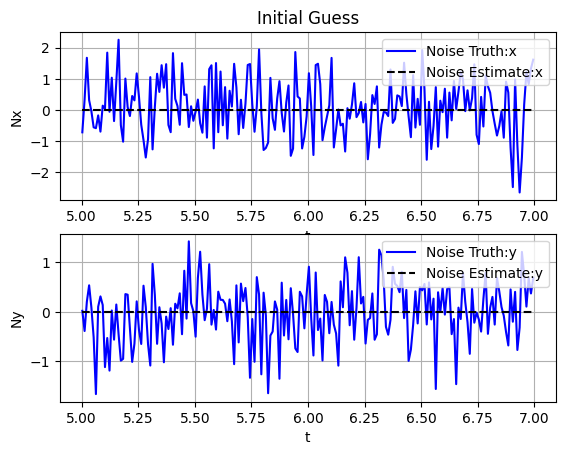

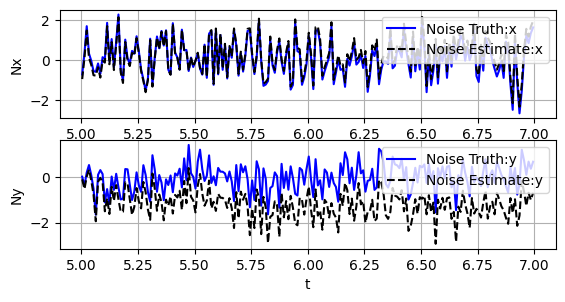

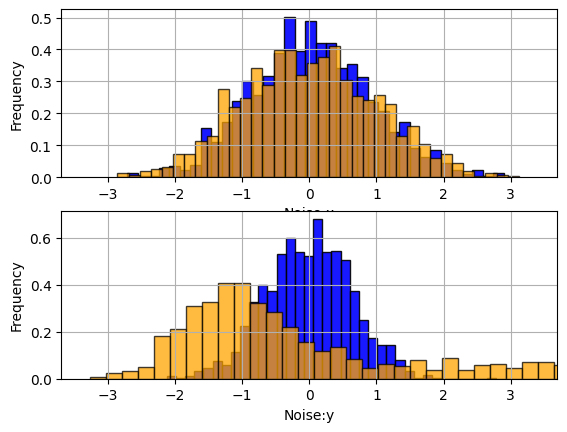

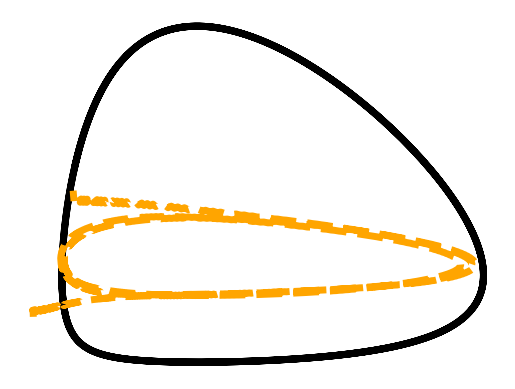

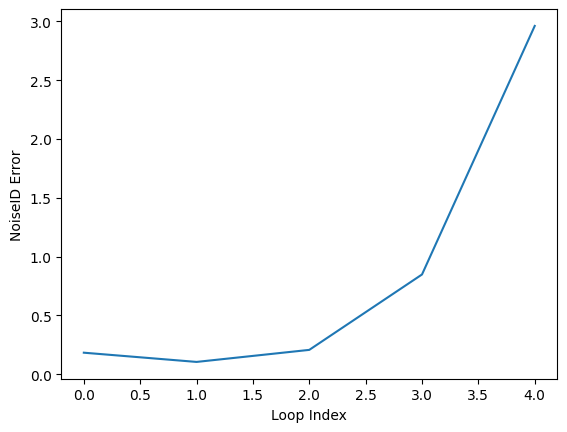

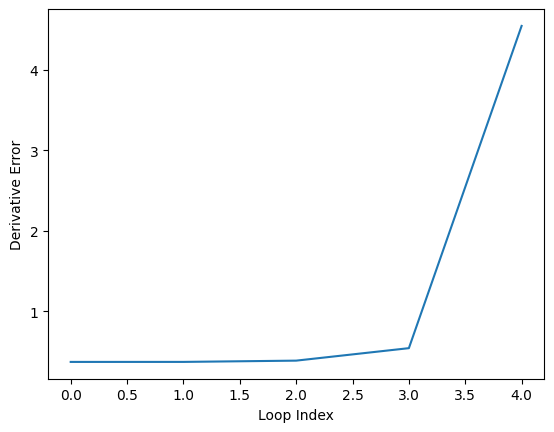

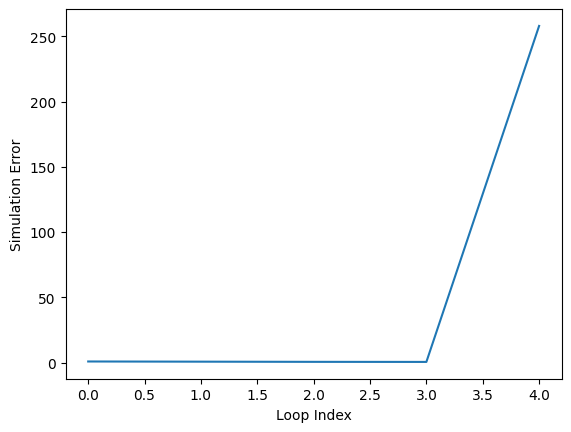

In [ ]:
#%% Define how many percent of noise you need
NoisePercentage=30

#%% Simulate
# Define the random seed for the noise generation
np.random.seed(4)

# Define the parameters
p0=np.array([1,0.5])

# Define the initial conditions
x0=np.array([1,2])

# Define the time points
T=15.0
dt=0.01

t=np.linspace(0.0,T,int(T/dt))

# Now simulate the system
x=odeint(Lotka,x0,t,args=(p0,),rtol = 1e-12, atol = 1e-12)
dx=np.transpose(Lotka(np.transpose(x), 0, p0))

# Get the size info
stateVar,dataLen=np.transpose(x).shape

# Generate the noise
NoiseMag=[np.std(x[:,i])*NoisePercentage*0.01 for i in range(stateVar)]
Noise=np.hstack([NoiseMag[i]*np.random.randn(dataLen,1) for i in range(stateVar)])

# Add the noise and get the noisy data
xn=x+Noise

# Test the SINDy
N_SINDy_Iter=15
disp=0
NormalizeLib=0
libOrder=3
lam=0.2

# SoftStart?
softstart=0

#%% Now plot the result of Lorenz

lw=5

plt.figure()
pp1=plt.plot(x[:,0],x[:,1],linewidth=lw,color='k',linestyle='-')
pp1=plt.plot(xn[:,0],xn[:,1],linewidth=1,color='red',linestyle='--')
plt.ylabel('x')
plt.grid(False)
plt.axis('off')
#plt.savefig("Lotka_NoiseLevel"+str(NoisePercentage)+".pdf")

#%% Define a neural network
# Check the GPU status
CheckGPU()

# Define the data type
dataType=tf.dtypes.float32

dh=tf.constant(dt)

#%% Define the data
# Define the prediction step
q=1

# Get the middel part of the measurement data (it will be define as constant)
Y=tf.constant(xn,dtype=dataType)
Y0=tf.constant(GetInitialCondition(xn,q,dataLen),dtype=dataType)

# Ge the forward and backward measurement data (it is a constant that wouldn't change)
Ypre_F,Ypre_B=SliceData(xn,q,dataLen)
Ypre_F=tf.constant(Ypre_F,dtype=dataType)
Ypre_B=tf.constant(Ypre_B,dtype=dataType)

# Get the weight for the error
ro=0.9
weights=tf.constant(DecayFactor(ro,stateVar,q),dtype=dataType)

if softstart==1:
    # Soft Start
    NoiseEs,xes=approximate_noise(np.transpose(xn), 20)
    NoiseEs=np.transpose(NoiseEs)
    xes=np.transpose(xes)
else:
    # Hard Start
    NoiseEs=np.zeros((xn.shape[0],xn.shape[1]))
    xes=xn-NoiseEs

dxes=CalDerivative(xes,dt,1)

# Get the initial guess of noise, we make a random guess here. For beteer performance you could first smooth the data and guess the noise.
NoiseVar=tf.Variable(NoiseEs,dtype=tf.dtypes.float32)

# Get the initial guess of the SINDy parameters
Theta=Lib(xes,libOrder)

Xi0=SINDy(Theta,dxes,lam,N_SINDy_Iter,disp,NormalizeLib)
print(Xi0)

# Define the initial guess of the selection parameters
Xi=tf.Variable(Xi0,dtype=dataType)

# Set the initial active matrix
Xi_act=tf.constant(np.ones(Xi0.shape),dtype=dataType)

#%% First plot the noise: true v.s. identified
StartIndex=500 # Choose how many noise data point you would like to plot
EndIndex=700

plt.figure()
plt.subplot(2,1,1)
plt.title("Initial Guess")
pp1=plt.plot(t[StartIndex:EndIndex],Noise[StartIndex:EndIndex,0],linewidth=1.5,color='b')
pp1=plt.plot(t[StartIndex:EndIndex],NoiseVar.numpy()[StartIndex:EndIndex,0],linewidth=1.5,color='k',linestyle='--')
plt.ylabel('Nx')
plt.xlabel('t')
plt.legend(['Noise Truth:x', 'Noise Estimate:x'],loc='upper right')
plt.grid(True)

plt.subplot(2,1,2)
pp1=plt.plot(t[StartIndex:EndIndex],Noise[StartIndex:EndIndex,1],linewidth=1.5,color='b')
pp1=plt.plot(t[StartIndex:EndIndex],NoiseVar.numpy()[StartIndex:EndIndex,1],linewidth=1.5,color='k',linestyle='--')
plt.ylabel('Ny')
plt.xlabel('t')
plt.legend(['Noise Truth:y', 'Noise Estimate:y'],loc='upper right')
plt.grid(True)


#%% Define the optimizer
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001,epsilon=1e-09)

#%% Finally start training!
Nloop=5
N_train=3000

# Set a list to store the noise value
NoiseList=[]
NoiseIDList_SingleRun=[]
TrainTimeList_SingleRun=np.zeros((Nloop,1))
Enoise_error_List_SingleRun=np.zeros((Nloop,1))
Evector_field_error_list_SingleRun=np.zeros((Nloop,1))
Epre_error_list_SingleRun=np.zeros((Nloop,1))
x_sim_list_SingleRun=[]
Xi_List_SingleRun=[]

for k in range(Nloop):
    print("Runing the loop ",str(k+1))
    # Denoise the signal
    NoiseID,totalTime=Train_NSS_SINDy(Y,Y0,Ypre_F,Ypre_B,NoiseVar,Xi,Xi_act,weights,dt,q,stateVar,dataLen,optimizer,N_train)

    print("\t Current loop takes ",totalTime)
    # After the first iteration, minus the noise identified from the noisy measurement data
    xes=xn-NoiseID
    xes=xes[q+1:-q-1,:]
    dxes=CalDerivative(xes,dt,1)

    print("Current Xi result")
    print(Xi)

    # Do SINDy on the denoised data
    Theta=Lib(xes,libOrder)
    Xi0=SINDy(Theta,dxes,lam,N_SINDy_Iter,disp,NormalizeLib)

    # Do SINDy on the denoised data
    index_min=abs(Xi.numpy())>lam
    Xi_act_dum=Xi_act.numpy()*index_min.astype(int)
    Xi_num=Xi.numpy()
    Xi_num=Xi_num*Xi_act_dum
    index_min=Xi_act_dum.astype(bool)

    # Regress
    for r in range(xes.shape[1]):
        Xi_num[index_min[:,r],r]=solve_minnonzero(Theta[:,index_min[:,r]],dxes[:,r])

    # Print the new initial start point
    print("New Xi result")
    print(Xi_num)

    # Determine which term should we focus on to optimize next
    Xi_act=tf.constant(Xi_act_dum,dtype=tf.dtypes.float32)
    Xi=tf.Variable(Xi_num,dtype=tf.dtypes.float32)

    # Calculate the performance
    Enoise_error,Evector_field_error,Epre_error,x_sim=ID_Accuracy_SINDy(x,dx,Noise,NoiseID,LibGPU,Xi,dataLen,dt)

    # Print the performance
    print("\t\t The error between the true noise and estimated noise is:",Enoise_error,"\n")
    print("\t\t The error between the true vector field and estimated vector field is:",Evector_field_error,"\n")
    print("\t\t The error between the true trajector and simulted trajectory is:",Epre_error,"\n")

    NoiseIDList_SingleRun.append(NoiseID)
    x_sim_list_SingleRun.append(x_sim)
    TrainTimeList_SingleRun[k]=totalTime
    Enoise_error_List_SingleRun[k]=Enoise_error
    Evector_field_error_list_SingleRun[k]=Evector_field_error
    Epre_error_list_SingleRun[k]=Epre_error
    Xi_List_SingleRun.append(Xi.numpy())

#%% Now plot the noise signal speration result

# First plot the noise: true v.s. identified
StartIndex=500 # Choose how many noise data point you would like to plot
EndIndex=700

plt.figure()
plt.subplot(3,1,1)
pp1=plt.plot(t[StartIndex:EndIndex],Noise[StartIndex:EndIndex,0],linewidth=1.5,color='b')
pp1=plt.plot(t[StartIndex:EndIndex],NoiseID[StartIndex:EndIndex,0],linewidth=1.5,color='k',linestyle='--')
plt.ylabel('Nx')
plt.xlabel('t')
plt.legend(['Noise Truth:x', 'Noise Estimate:x'],loc='upper right')
plt.grid(True)

plt.subplot(3,1,2)
pp1=plt.plot(t[StartIndex:EndIndex],Noise[StartIndex:EndIndex,1],linewidth=1.5,color='b')
pp1=plt.plot(t[StartIndex:EndIndex],NoiseID[StartIndex:EndIndex,1],linewidth=1.5,color='k',linestyle='--')
plt.ylabel('Ny')
plt.xlabel('t')
plt.legend(['Noise Truth:y', 'Noise Estimate:y'],loc='upper right')
plt.grid(True)

#%%
n_bins=int(180/5)
x_scale=np.linspace(-4*max(NoiseMag), 4*max(NoiseMag), 1000)

plt.figure()
plt.subplot(2,1,1)
plt.grid(True)
pp6=plt.hist(Noise[:,0], bins = n_bins, color = 'blue', alpha=0.9,edgecolor = 'black',density=True)
pp6=plt.hist(NoiseID[:,0], bins = n_bins, color = 'orange', alpha=0.75,edgecolor = 'black',density=True)
plt.ylabel('Frequency')
plt.xlabel('Noise:x')
axes = plt.gca()
axes.set_xlim([-4*max(NoiseMag),4*max(NoiseMag)])
#axes.set_ylim([0,0.65])

plt.subplot(2,1,2)
plt.grid(True)
pp6=plt.hist(Noise[:,1], bins = n_bins, color = 'blue', alpha=0.9,edgecolor = 'black',density=True)
pp6=plt.hist(NoiseID[:,1], bins = n_bins, color = 'orange', alpha=0.75,edgecolor = 'black',density=True)
plt.ylabel('Frequency')
plt.xlabel('Noise:y')
axes = plt.gca()
axes.set_xlim([-4*max(NoiseMag),4*max(NoiseMag)])
#axes.set_ylim([0,0.65])
#plt.savefig('Percent'+str(NoisePercentage)+'_Distribution.pdf')

#%%
plt.figure()
pp1=plt.plot(x[:,0],x[:,1],linewidth=lw,color='k',linestyle='-')
pp1=plt.plot(xn[:,0]-NoiseID[:,0],xn[:,1]-NoiseID[:,1],linewidth=lw,color='orange',linestyle='--')
plt.ylabel('x')
plt.grid(False)
plt.axis('off')
#plt.savefig("Lotka_NoiseLevel_Denoised"+str(NoisePercentage)+".pdf")

#%%
Enoise_error,Evector_field_error,Epre_error,x_sim=ID_Accuracy_SINDy(x,dx,Noise,NoiseID,LibGPU,Xi,dataLen,dt)

print("The error between the true noise and estimated noise is:",Enoise_error)
print("The error between the true vector field and estimated vector field is:",Evector_field_error)
print("The error between the true trajector and simulted trajectory is:",Epre_error)


#%%

plt.figure()
plt.plot(Enoise_error_List_SingleRun)
plt.ylabel('NoiseID Error')
plt.xlabel('Loop Index')

plt.figure()
plt.plot(Evector_field_error_list_SingleRun)
plt.ylabel('Derivative Error')
plt.xlabel('Loop Index')

plt.figure()
plt.plot(Epre_error_list_SingleRun)
plt.ylabel('Simulation Error')
plt.xlabel('Loop Index')

In [ ]:
# Use Pysindy in python library

In [ ]:
!pip install pysindy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.0/121.0 kB 4.2 MB/s eta 0:00:00


In [ ]:
!pip install scienceplots

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import pysindy as ps
import scienceplots
plt.style.use(["science", "notebook", "grid"])
plt.rc('text', usetex=True)
plt.rc('font', family='serif')
def lotka_volterra(t, x, params = [1, 1, 1, 1]):
    """
    Lotka-Volterra data

    Args:
        t (array): Time
        x (array): Data
        params (array, optional): parameters alpha, beta, gamma, delta. Defaults to [2/3, 4/3, 1, 1]

    Returns:
        array: Lotka-Volterra data
    """
    assert len(params) == 4
    return [params[0] * x[0] - params[1] * x[0] * x[1], params[2] * x[0] * x[1] - params[3] * x[1]]

In [ ]:
x0 = [1.5, 1]
delta_t = 0.01
t = np.arange(0, 20, delta_t)
np.random.seed(42)
x_train = solve_ivp(lotka_volterra, (t[0], t[-1]), x0, t_eval=t, rtol = 1e-12, method = "LSODA", atol = 1e-12).y.T
x_dot = np.array([lotka_volterra(0, x_train[t]) for t in range(t.size)])
x = x_train[:, 0]
y = x_train[:, 1]
#plt.figure(figsize=(6, 5))
#plt.plot(x, y, "k")
#plt.xlabel("$x$")
#plt.ylabel("$y$")
#plt.title("Phase Plot with initial condition $(1,2)$")
#plt.show()

In [ ]:
opt = ps.STLSQ(threshold=0.05)
lib = ps.PolynomialLibrary(degree=3)
diff = ps.FiniteDifference()
model = ps.SINDy(optimizer=opt, feature_library=lib, differentiation_method=diff, feature_names=["x", "y"])
model.fit(x_train, t, x_dot)
model.print(precision = 5)
model.score(x_train, t, x_dot)

(x)' = 0.00643 1 + 0.61752 x + -0.19032 y + 0.19777 x^2 + -0.09277 x^3 + -0.19633 x^2 y + -0.28845 x y^2
(y)' = -0.00674 1 + 0.19044 x + -0.61684 y + -0.19836 y^2 + 0.28837 x^2 y + 0.19635 x y^2 + 0.09294 y^3


0.9999995253066065

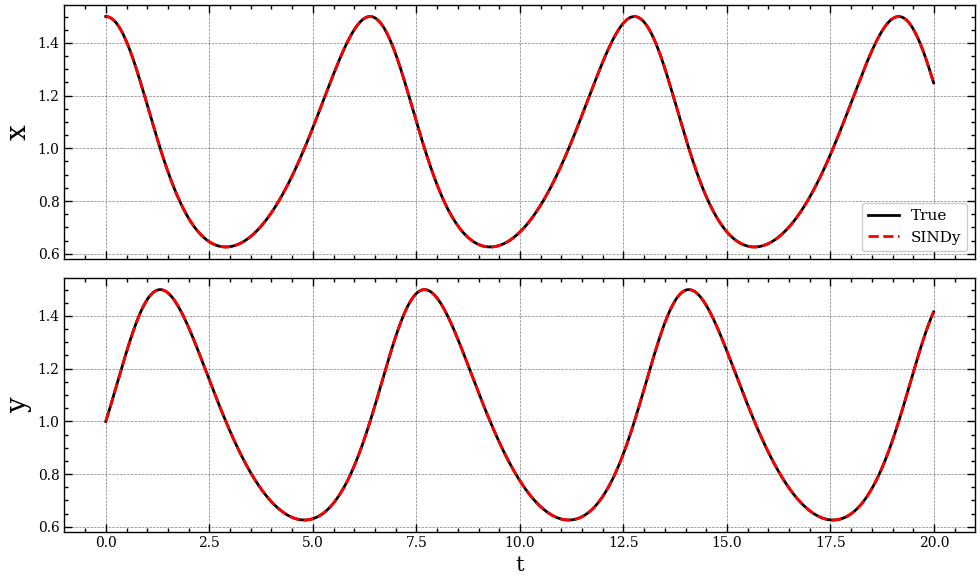

In [ ]:
import matplotlib.pyplot as plt

# Disable LaTeX rendering
plt.rcParams['text.usetex'] = False

def plot_xyz(sim_x, sim_y, x, y, name="lotka-clean", title="Clean Data"):
    """
    Plots dynamics in x, y.

    Args:
        sim_x: Simulated data for x
        sim_y: Simulated data for y
        x: True data for x
        y: True data for y
        name: Saving name for png
        title: Part of text to put in the title of the plot
    """
    fig, axes = plt.subplots(2, 1, figsize=(10, 6))

    axes[0].plot(t, x, label='True', color='k')
    axes[0].plot(t, sim_x, 'r--', label='SINDy')
    axes[0].set_ylabel('x', fontsize=20)
    axes[0].legend(loc="lower right", prop={'size': 11})
    axes[0].xaxis.set_ticklabels([])
    axes[0].yaxis.set_tick_params(labelsize=10)

    axes[1].plot(t, y, color='k')
    axes[1].plot(t, sim_y, 'r--')
    axes[1].set_xlabel('t', fontsize=15)
    axes[1].set_ylabel('y', fontsize=20)
    axes[1].xaxis.set_tick_params(labelsize=10)
    axes[1].yaxis.set_tick_params(labelsize=10)

    plt.tight_layout()
    plt.show()

# Call the function with your data
plot_xyz(x_sim, y_sim, x, y)

In [ ]:
#mse